# Qualidades, defeitos, marcas no corpo, ofício e cor, por período

Este caderno responde: **o que os anúncios dizem sobre a pessoa anunciada, e isso muda entre os períodos legais?**
Para cada anúncio do corpus `corp3` (campos `c7`) vemos se o texto **original** cita ao menos um termo de cada categoria:

- **qualidades** (`sem vícios`, `fiel`, `boa conduta`, `carinhosa`, `prendada`, `de boa figura`...);
- **defeitos** (`vícios`, `moléstias`, `defeito`, `doente`, `aleijado`...), sempre **sem a negação**: "sem vícios" conta como qualidade e não como defeito;
- **marcas no corpo** (`cicatriz`, `sinal`, `bexigas`, `falta de dentes`, `ferida`...), só nas **fugas**, que são os anúncios que descrevem o corpo;
- **ofício** (`c_oficios`) e **cor** (`c_cores`), que já estão nos campos extraídos.

As listas de termos estão em `src/hdb/categorias.py`; cada termo só entrou se aparece em pelo menos 5 anúncios do corpus.
A busca tolera **1 erro de OCR** em palavras de 7 letras ou mais (por exemplo, `cicatrir` vale como `cicatriz`); palavras curtas têm de estar certas.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca**, não por sorteio, e o OCR é sujo: o que não foi lido não aparece.
> Os números descrevem **o texto dos anúncios**, não as pessoas. Quem escrevia o anúncio queria vender, alugar ou recapturar:
> as "qualidades" são **argumentos de venda**, e os "defeitos", o que se admitia ou se negava ("não tem vícios").
> Uma barra com **n < 30** é frágil e vem marcada.

## Preparação: ler o banco
Lemos os anúncios do corpus em blocos de 1000 linhas e marcamos as categorias em cada texto original.

In [1]:
import sys, html, re
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from hdb import config
from hdb.banco import BancoSupabase
from hdb.campos import _simples
from hdb.categorias import QUALIDADES, DEFEITOS, MARCAS_CORPO, ocorrencias

db = BancoSupabase().cliente      # só leitura; lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

corpus_ids = set(ler_tudo(lambda: db.table("anuncio_corpus").select("anuncio_id")
                          .eq("versao", config.VERSAO_CORPUS).order("anuncio_id"))["anuncio_id"])
df = ler_tudo(lambda: db.table("anuncios_completos")
              .select("id,periodo_legal,c_tipo,ano,texto,c_oficios,c_cores")
              .in_("versao", list(config.VERSOES_ANUNCIOS)).eq("c_versao", config.VERSAO_CAMPOS).order("id"))
df = df[df["id"].isin(corpus_ids)].reset_index(drop=True)
print(f"{len(df)} anúncios no corpus {config.VERSAO_CORPUS} (campos {config.VERSAO_CAMPOS})")
if len(df) != 2191:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2191 anúncios e agora são {len(df)}: "
          "confira os números dos textos antes de usar.")

2191 anúncios no corpus corp3 (campos c7)


In [2]:
PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]
df = df[df["periodo_legal"].notna() & (df["periodo_legal"] != "depois de 1888")].copy()
df["periodo"] = pd.Categorical(df["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)

TIPOS = ["fuga", "venda", "aluguel", "ama_de_leite", "compra"]
ROTULO_TIPO = {"fuga": "Fuga", "venda": "Venda", "aluguel": "Aluguel", "ama_de_leite": "Ama de leite", "compra": "Compra"}
COR = {"fuga": "#D55E00", "venda": "#0072B2", "aluguel": "#009E73", "ama_de_leite": "#CC79A7", "compra": "#E69F00"}  # Okabe-Ito
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
MIN_N = 30

# Termos de cada anúncio, no texto original (sem negação nos defeitos e nas marcas)
def termos(lista, texto):
    return list(dict.fromkeys(c for c, _, _ in ocorrencias(texto, lista, negacao=lista is not QUALIDADES)))
df["qualidades"] = df["texto"].map(lambda t: termos(QUALIDADES, t))
df["defeitos"] = df["texto"].map(lambda t: termos(DEFEITOS, t))
df["marcas"] = df["texto"].map(lambda t: termos(MARCAS_CORPO, t))
df["oficios"] = df["c_oficios"].map(lambda v: list(v) if isinstance(v, (list, np.ndarray)) else [])
df["cores"] = df["c_cores"].map(lambda v: list(v) if isinstance(v, (list, np.ndarray)) else [])

CATEGORIAS = {  # coluna -> (rótulo, tipos que entram)
    "qualidades": ("Qualidades", TIPOS), "defeitos": ("Defeitos", TIPOS),
    "marcas": ("Marcas no corpo", ["fuga"]), "oficios": ("Ofício", TIPOS), "cores": ("Cor", TIPOS),
}
print(df.groupby(["periodo", "c_tipo"], observed=True).size().unstack(fill_value=0))

c_tipo         aluguel  ama_de_leite  compra  fuga  venda
periodo                                                  
antes de 1831       18            25       0    68     41
1831–1850          159            71      17   108    210
1850–1871          494           111      16   178    286
1871–1888          181            30       3    93     82


## 1. Quantos anúncios têm cada categoria
Para cada **período** e **tipo**, a **porcentagem de anúncios** com pelo menos um termo da categoria, com o **n** (total de anúncios daquele grupo) em cada barra.
Barras **hachuradas** têm n < 30: são frágeis, **não tire conclusão delas**. As marcas no corpo só entram para as fugas.

In [3]:
def tabela(coluna, tipos):
    """% de anúncios com >= 1 termo, por período (linhas) e tipo (colunas), com os n."""
    linhas = []
    for per in PERIODOS:
        for t in tipos:
            g = df[(df["periodo"] == per) & (df["c_tipo"] == t)]
            k = int(g[coluna].map(len).gt(0).sum())
            linhas.append({"periodo": per, "tipo": t, "n": len(g), "com": k, "pct": 100 * k / len(g) if len(g) else np.nan})
    return pd.DataFrame(linhas)

def grafico(coluna):
    rotulo, tipos = CATEGORIAS[coluna]
    t = tabela(coluna, tipos)
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    largura = 0.8 / len(tipos)
    for j, tp in enumerate(tipos):
        s = t[t["tipo"] == tp].reset_index(drop=True)
        x = np.arange(len(PERIODOS)) + (j - (len(tipos) - 1) / 2) * largura
        for i, r in s.iterrows():
            frag = r["n"] < MIN_N
            if r["n"] == 0:
                continue
            ax.bar(x[i], r["pct"], largura * 0.92, color=COR[tp], alpha=0.45 if frag else 1, hatch="//" if frag else None,
                   edgecolor="white", label=ROTULO_TIPO[tp] if i == 0 or not any(
                       h.get_label() == ROTULO_TIPO[tp] for h in ax.patches) else None)
            ax.text(x[i], r["pct"] + 0.8, f"{r['pct']:.0f}%\nn={int(r['n'])}", ha="center", va="bottom", fontsize=7.5)
    ax.set_xticks(range(len(PERIODOS))); ax.set_xticklabels(PERIODOS)
    ax.set_ylim(0, max(10, np.nanmax(t["pct"]) * 1.3))
    ax.set_title(f"{rotulo}: % de anúncios com pelo menos um termo")
    ax.set_xlabel("Período legal"); ax.set_ylabel("% dos anúncios do grupo")
    if len(tipos) > 1:
        h, l = ax.get_legend_handles_labels()
        ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    fig.tight_layout(); plt.show()
    pequenos = t[(t["n"] < MIN_N) & (t["n"] > 0)]
    if len(pequenos):
        itens = ", ".join(f"{ROTULO_TIPO[r.tipo]} {r.periodo} (n={r.n})" for r in pequenos.itertuples())
        display(Markdown(f"**Atenção, n < {MIN_N}:** {itens}."))
    out = t.assign(tipo=t["tipo"].map(ROTULO_TIPO), pct=t["pct"].round(1))
    return out.pivot(index="periodo", columns="tipo", values="pct").reindex(PERIODOS), out.pivot(index="periodo", columns="tipo", values="n").reindex(PERIODOS)

### 2. Qualidades
Argumentos de venda e de aluguel: `sem vícios`, `fiel`, `boa conduta`, `carinhosa`, `de boa figura`...

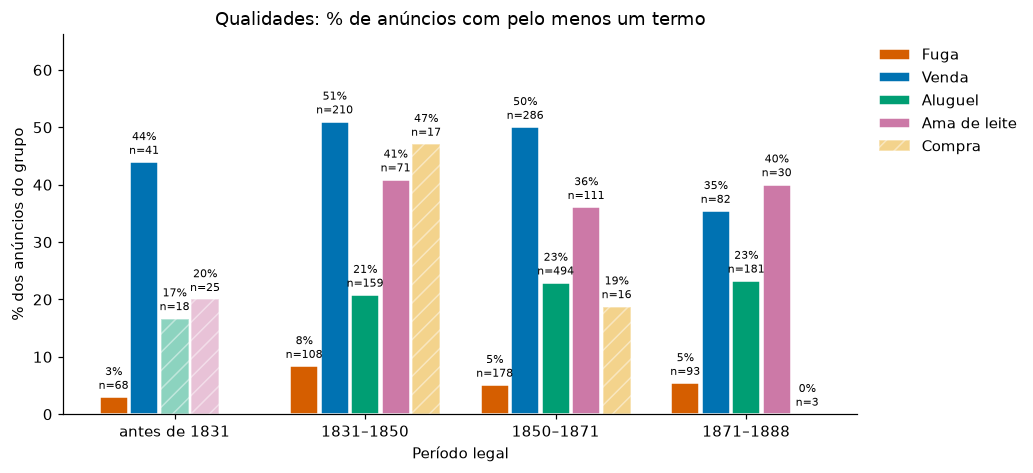

**Atenção, n < 30:** Aluguel antes de 1831 (n=18), Ama de leite antes de 1831 (n=25), Compra 1831–1850 (n=17), Compra 1850–1871 (n=16), Compra 1871–1888 (n=3).

**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,16.7,20.0,NaN,2.9,43.9
1831–1850,20.8,40.8,47.1,8.3,51.0
1850–1871,22.9,36.0,18.8,5.1,50.0
1871–1888,23.2,40.0,0.0,5.4,35.4


**n de cada barra**

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,18,25,0,68,41
1831–1850,159,71,17,108,210
1850–1871,494,111,16,178,286
1871–1888,181,30,3,93,82


In [4]:
pct, ns = grafico("qualidades")
display(Markdown("**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)"))
display(pct)
display(Markdown("**n de cada barra**"))
display(ns.astype("Int64"))

**O que se vê:** as **qualidades** aparecem em cerca de metade dos anúncios de **venda** (43,9% antes de 1831 com n = 41, e 51,0%, 50,0% e 35,4% depois), em 36% a 41% das **amas de leite** depois de 1831 e em 21% a 23% dos **aluguéis**. Nas **fugas** são raras (3% a 8%). O termo mais frequente é `perfeita` (172 anúncios), que muitas vezes é **habilidade** ("perfeita cozinheira") e não traço de caráter, então esse número infla um pouco. A queda das qualidades na venda em 1871–1888 (35,4%) tem n = 82.

### 3. Defeitos
O que o texto admite como defeito, **sem contar a negação**: "sem vícios" e "não tem defeito" **não** entram aqui. Poucos anúncios têm defeitos, então as porcentagens são pequenas.

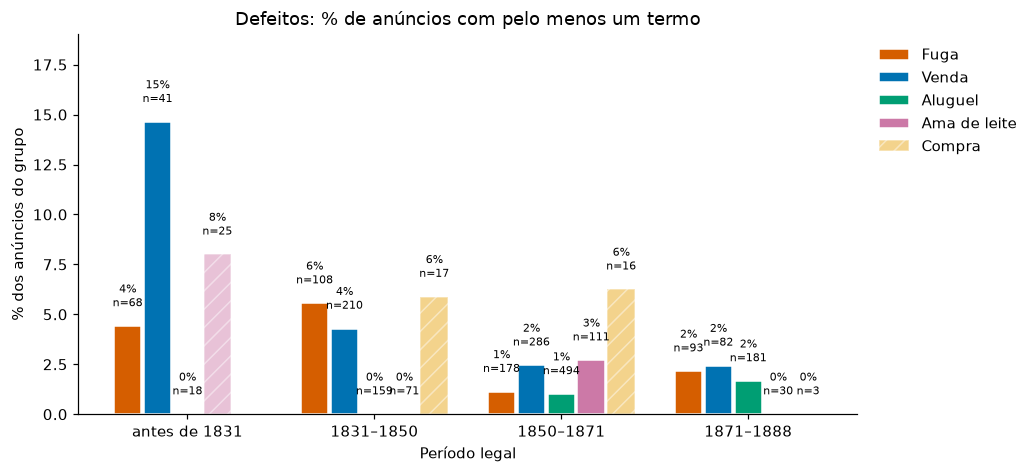

**Atenção, n < 30:** Aluguel antes de 1831 (n=18), Ama de leite antes de 1831 (n=25), Compra 1831–1850 (n=17), Compra 1850–1871 (n=16), Compra 1871–1888 (n=3).

**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,0.0,8.0,NaN,4.4,14.6
1831–1850,0.0,0.0,5.9,5.6,4.3
1850–1871,1.0,2.7,6.2,1.1,2.4
1871–1888,1.7,0.0,0.0,2.2,2.4


**n de cada barra**

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,18,25,0,68,41
1831–1850,159,71,17,108,210
1850–1871,494,111,16,178,286
1871–1888,181,30,3,93,82


In [5]:
pct, ns = grafico("defeitos")
display(Markdown("**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)"))
display(pct)
display(Markdown("**n de cada barra**"))
display(ns.astype("Int64"))

**O que se vê:** os **defeitos** são raros (0% a 6% na maior parte dos grupos). O que aparece é `vícios`, `defeito` e `moléstias` (poucos casos cada). O anúncio de venda descreve sobretudo a **ausência** de defeito ("sem vícios", "não tem moléstias"), que o caderno conta como qualidade. Com tão poucos casos, **não dá para comparar períodos**; o 14,6% das vendas antes de 1831 é 6 anúncios em 41.

### 4. Marcas no corpo (só fugas)
Cicatrizes, sinais, bexigas, falta de dentes, feridas e queimaduras: servem para reconhecer a pessoa fugida. `marca` sozinha não conta (nos anúncios de aluguel é "marcar" roupa).

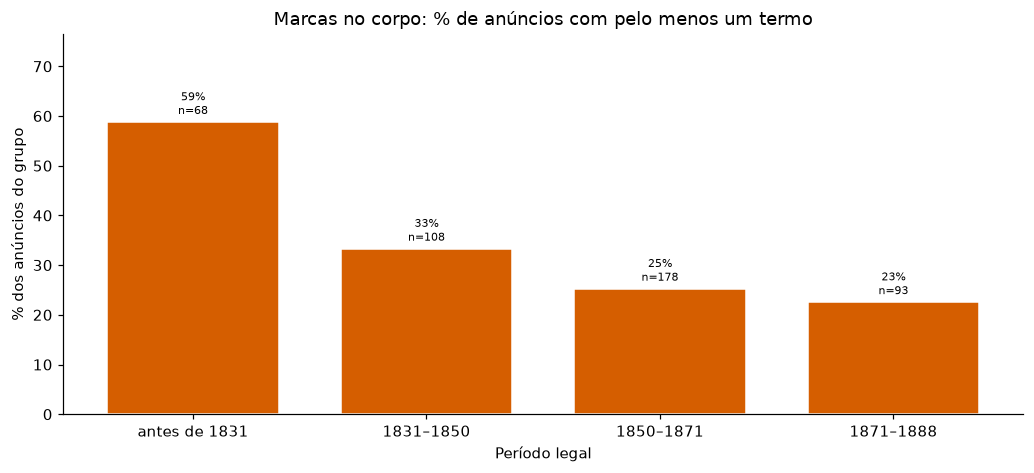

**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)

tipo,Fuga
periodo,
antes de 1831,58.8
1831–1850,33.3
1850–1871,25.3
1871–1888,22.6


**n de cada barra**

tipo,Fuga
periodo,
antes de 1831,68
1831–1850,108
1850–1871,178
1871–1888,93


In [6]:
pct, ns = grafico("marcas")
display(Markdown("**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)"))
display(pct)
display(Markdown("**n de cada barra**"))
display(ns.astype("Int64"))

**O que se vê (só fuga):** a citação de **marcas no corpo** cai de 58,8% antes de 1831 (n = 68) para 33,3% em 1831–1850, 25,3% em 1850–1871 e 22,6% em 1871–1888. Os termos mais frequentes são `signal` (55), `cicatriz` (26), `falta de dentes` (21), `ferida` (18) e `bexigas` (16). Ou seja, os anúncios mais antigos descrevem mais o corpo para reconhecer a pessoa; depois descrevem menos, ou o fazem com outras palavras. Os termos de **castigo** (`açoites`, `marca de ferro`) **não aparecem** em quantidade (zero ou menos de 5 casos), então este caderno **não mede a violência registrada nos anúncios**.

### 5. Ofício
Ofícios extraídos pelo campo `c_oficios` (cozinheiro, lavadeira, costureira, copeiro...).

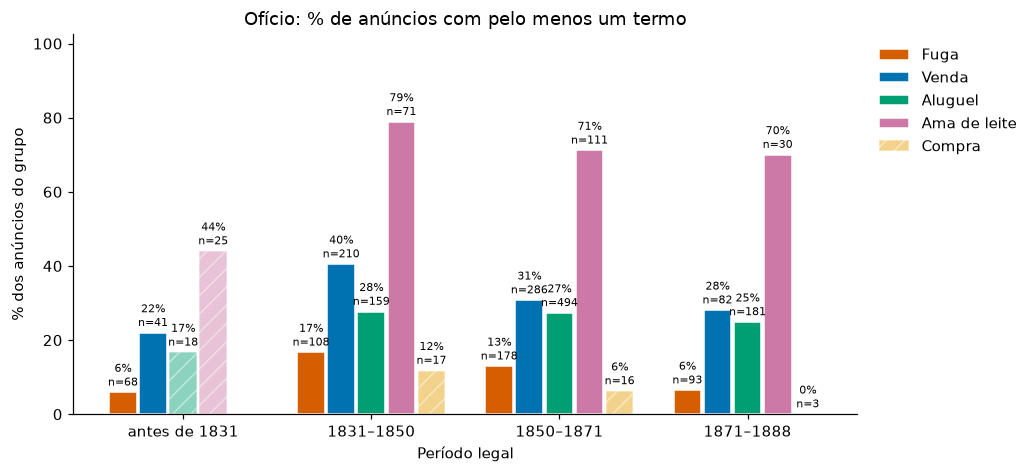

**Atenção, n < 30:** Aluguel antes de 1831 (n=18), Ama de leite antes de 1831 (n=25), Compra 1831–1850 (n=17), Compra 1850–1871 (n=16), Compra 1871–1888 (n=3).

**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,16.7,44.0,NaN,5.9,22.0
1831–1850,27.7,78.9,11.8,16.7,40.5
1850–1871,27.3,71.2,6.2,12.9,30.8
1871–1888,24.9,70.0,0.0,6.5,28.0


**n de cada barra**

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,18,25,0,68,41
1831–1850,159,71,17,108,210
1850–1871,494,111,16,178,286
1871–1888,181,30,3,93,82


In [7]:
pct, ns = grafico("oficios")
display(Markdown("**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)"))
display(pct)
display(Markdown("**n de cada barra**"))
display(ns.astype("Int64"))

**O que se vê:** o **ofício** é citado em 22% a 40% das **vendas**, em 25% a 28% dos **aluguéis** e em 6% a 17% das **fugas** (pico de 16,7% em 1831–1850). Em **ama de leite** é quase sempre `ama de leite` (44% a 79%), o que é trivial. Os ofícios mais citados são `cozinheiro` (164), `ama de leite` (155), `lavadeira` (70) e `mucama` (65).

### 6. Cor
Cores e qualidades de cor extraídas pelo campo `c_cores` (preto, pardo, crioulo, fula...). Os anúncios de fuga e de venda descrevem a cor de formas diferentes.

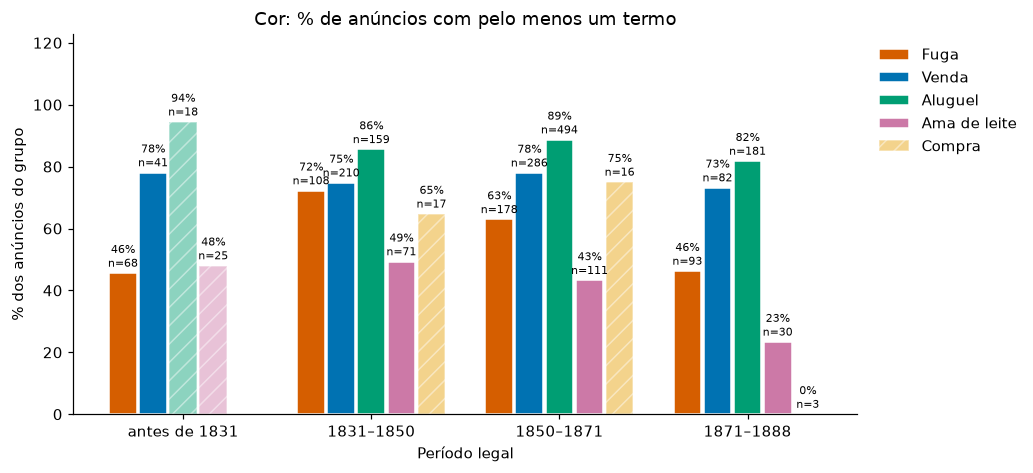

**Atenção, n < 30:** Aluguel antes de 1831 (n=18), Ama de leite antes de 1831 (n=25), Compra 1831–1850 (n=17), Compra 1850–1871 (n=16), Compra 1871–1888 (n=3).

**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,94.4,48.0,NaN,45.6,78.0
1831–1850,85.5,49.3,64.7,72.2,74.8
1850–1871,88.7,43.2,75.0,62.9,78.0
1871–1888,81.8,23.3,0.0,46.2,73.2


**n de cada barra**

tipo,Aluguel,Ama de leite,Compra,Fuga,Venda
periodo,,,,,
antes de 1831,18,25,0,68,41
1831–1850,159,71,17,108,210
1850–1871,494,111,16,178,286
1871–1888,181,30,3,93,82


In [8]:
pct, ns = grafico("cores")
display(Markdown("**% de anúncios com pelo menos um termo** (linhas: período; colunas: tipo)"))
display(pct)
display(Markdown("**n de cada barra**"))
display(ns.astype("Int64"))

**O que se vê:** a **cor** é citada em 82% a 94% dos **aluguéis**, em 73% a 78% das **vendas** e em 46% a 72% das **fugas**: nas fugas ela cai de 72,2% (1831–1850) para 46,2% (1871–1888). Na **ama de leite** vai de 49,3% a 23,3%. Os termos mais frequentes são `preto` (1.233 anúncios), `pardo` (256) e `crioulo` (107). A cor é a categoria **menos informativa** para separar períodos, porque quase todo anúncio a usa.

## 7. Termos mais frequentes
Os 10 termos mais frequentes de cada categoria: em **quantos anúncios** cada um aparece (conta-se uma vez por anúncio).

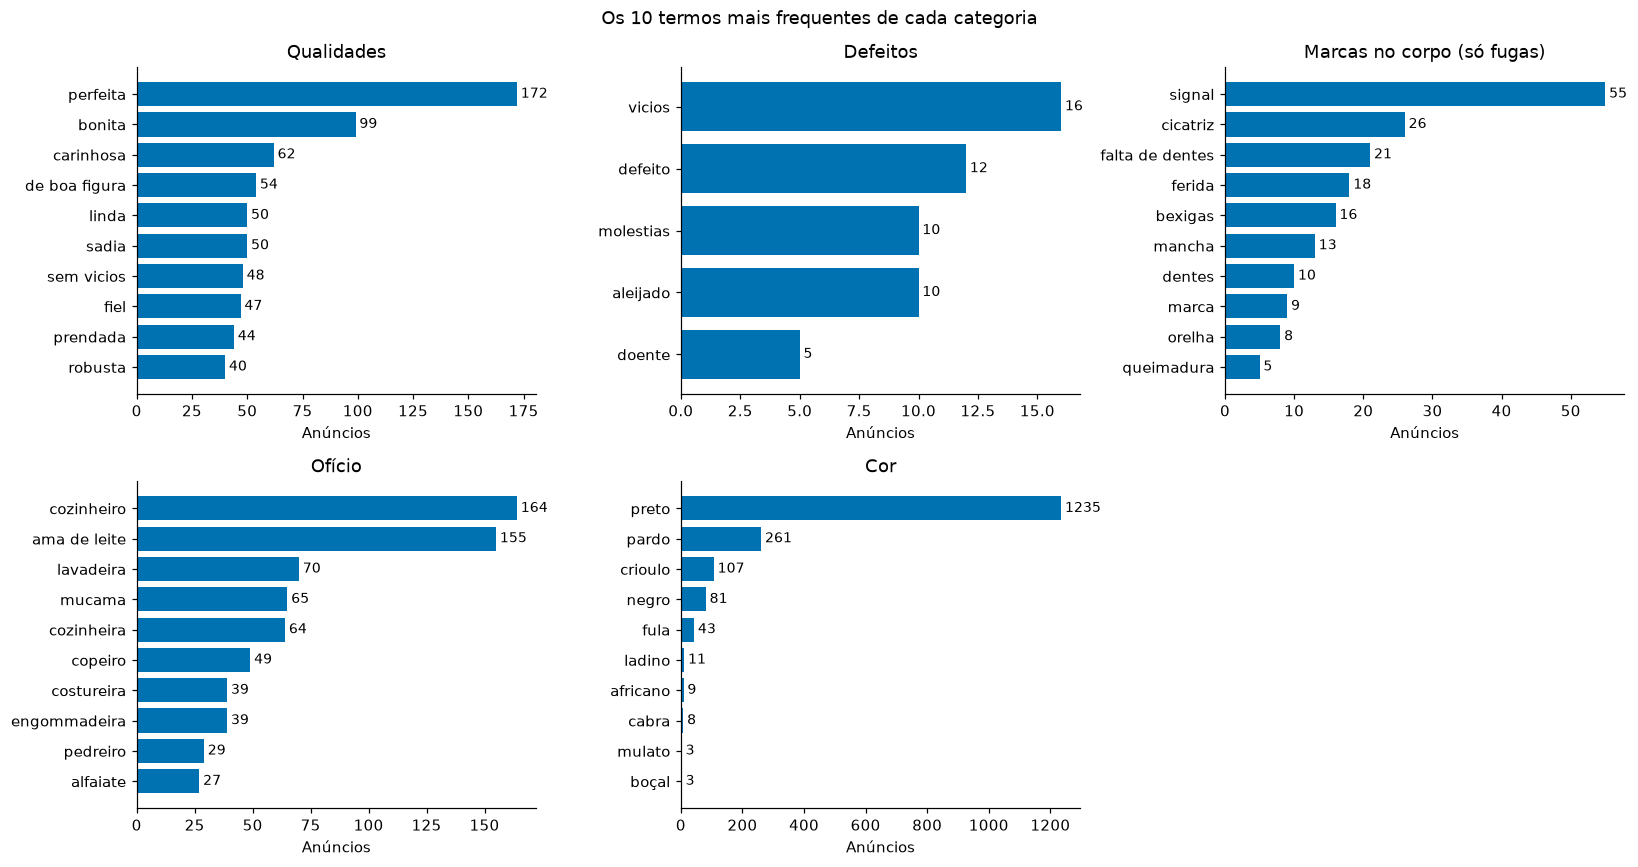

Qualidades {'perfeita': 172, 'bonita': 99, 'carinhosa': 62, 'de boa figura': 54, 'linda': 50, 'sadia': 50, 'sem vicios': 48, 'fiel': 47, 'prendada': 44, 'robusta': 40}
Defeitos {'vicios': 16, 'defeito': 12, 'molestias': 10, 'aleijado': 10, 'doente': 5}
Marcas no corpo {'signal': 55, 'cicatriz': 26, 'falta de dentes': 21, 'ferida': 18, 'bexigas': 16, 'mancha': 13, 'dentes': 10, 'marca': 9, 'orelha': 8, 'queimadura': 5}
Ofício {'cozinheiro': 164, 'ama de leite': 155, 'lavadeira': 70, 'mucama': 65, 'cozinheira': 64, 'copeiro': 49, 'costureira': 39, 'engommadeira': 39, 'pedreiro': 29, 'alfaiate': 27}
Cor {'preto': 1235, 'pardo': 261, 'crioulo': 107, 'negro': 81, 'fula': 43, 'ladino': 11, 'africano': 9, 'cabra': 8, 'mulato': 3, 'boçal': 3}


In [9]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for ax, (coluna, (rotulo, _)) in zip(eixos.ravel(), CATEGORIAS.items()):
    base = df[df["c_tipo"] == "fuga"] if coluna == "marcas" else df
    c = base[coluna].explode().dropna().value_counts().head(10)
    ax.barh(c.index[::-1], c.values[::-1], color="#0072B2")
    for y, v in enumerate(c.values[::-1]):
        ax.text(v + c.max() * 0.01, y, str(v), va="center", fontsize=9)
    ax.set_title(f"{rotulo}" + (" (só fugas)" if coluna == "marcas" else "")); ax.set_xlabel("Anúncios")
eixos.ravel()[-1].set_axis_off()
fig.suptitle("Os 10 termos mais frequentes de cada categoria"); fig.tight_layout(); plt.show()
for coluna, (rotulo, _) in CATEGORIAS.items():
    base = df[df["c_tipo"] == "fuga"] if coluna == "marcas" else df
    print(rotulo, base[coluna].explode().dropna().value_counts().head(10).to_dict())

**Os termos mais frequentes** mostram o vocabulário real que sustenta cada categoria. Duas cautelas: `perfeita` conta como qualidade mesmo quando é habilidade, e vários termos que sugeri (bêbado, ladrão, achaques, "marca de ferro") **não aparecem** no corpus (zero ocorrências) e por isso não estão nas listas.

## 8. Três exemplos reais de cada categoria
Trechos de 160 caracteres do texto original, com o termo em **destaque**. O OCR é sujo e os trechos aparecem como foram lidos.
Os exemplos são sorteados com semente fixa, um de cada período quando possível.

In [10]:
def trecho(texto, termo, largura=160):
    """Trecho com o termo destacado, ou None se o termo não está no texto."""
    ach = ocorrencias(texto, [termo], negacao=False)
    if not ach:
        return None
    _, i, j = ach[0]
    ini = max(0, min(i - (largura - (j - i)) // 2, len(texto) - largura))
    fim = min(len(texto), ini + largura)
    t = lambda a, b: html.escape(re.sub(r"\s+", " ", texto[a:b]))
    return ("…" if ini else "") + t(ini, i) + f"<b style='background:#ffe08a'>{t(i, j)}</b>" + t(j, fim) + ("…" if fim < len(texto) else "")

rng = np.random.default_rng(2024)
for coluna, (rotulo, _) in CATEGORIAS.items():
    base = df[df["c_tipo"] == "fuga"] if coluna == "marcas" else df
    base = base[base[coluna].map(len) > 0]
    display(Markdown(f"### {rotulo}"))
    escolhidos, usados = [], set()
    for per in rng.permutation(PERIODOS).tolist() + PERIODOS:
        g = base[(base["periodo"] == per) & ~base["id"].isin(usados)]
        for k in rng.permutation(len(g)).tolist():
            r = g.iloc[k]
            termo = rng.choice(r[coluna])
            alvo = _simples(termo) if coluna in ("oficios", "cores") else termo
            frag = trecho(r["texto"], alvo)
            if frag:
                escolhidos.append((r, termo, frag)); usados.add(r["id"]); break
        if len(escolhidos) == 3:
            break
    for r, termo, frag in escolhidos:
        display(HTML(f"<p style='margin:4px 0'><small>#{r['id']} · {r['periodo']} · {ROTULO_TIPO.get(r['c_tipo'], r['c_tipo'])} · termo: <i>{html.escape(termo)}</i></small><br>{frag}</p>"))

### Qualidades

### Defeitos

### Marcas no corpo

### Ofício

### Cor

**Os exemplos reais** servem para conferir que os termos fazem sentido. Se um exemplo estiver errado (por exemplo, um termo de outra coisa), o termo deve sair da lista em `src/hdb/categorias.py`. Lembrete: o termo `fujão/fugidio` foi **retirado** porque casava com `fugido` por erro de OCR em 96 anúncios.